In [3]:
#!pip install pennylane -q

import numpy as np
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [4]:
# Generate a small non-linear dataset (fewer samples as kernel matrices scale O(N^2))
X, y = make_moons(n_samples=60, noise=0.15, random_state=42)
# Keep labels as {0, 1} since classical SVC handles binary targets natively

# Scale features to fit nicely within [0, 2*pi] for quantum angle rotation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42
)

### DEFINING THE QUANTUM KERNEL CIRCUIT (Z-FEATURE MAP)

In [7]:
n_qubits = 2
dev = qml.device("default.qubit", wires=n_qubits)

def angle_embedding_map(x):
    """
    Encodes classical data vector x into a quantum state.
    """
    for i in range(n_qubits):
        qml.Hadamard(wires=i)
        qml.RZ(x[i], wires=i)
    # Add entangling gates to introduce non-linear quantum correlations
    qml.CNOT(wires=[0, 1])
    qml.RZ(x[0] * x[1], wires=1)


@qml.qnode(dev)
def quantum_kernel_circuit(x1, x2):
    """
    Computes the transition amplitude |<phi(x2) | phi(x1)>|^2
    which corresponds to the inner product in the Hilbert space.
    """
    # Apply feature map for data point x1: |phi(x1)>
    angle_embedding_map(x1)

    # Apply adjoint (inverse) feature map for data point x2: <phi(x2)|
    qml.adjoint(angle_embedding_map)(x2)

    # Return the probability of measuring the all-zero state |00><00|
    return qml.probs(wires=range(n_qubits))


def compute_quantum_kernel(x1, x2):
    """
    Extracts the absolute probability of the |00...0> state.
    """
    return quantum_kernel_circuit(x1, x2)[0]

### BUILDING THE QUANTUM KERNEL MATRICES

In [8]:
def get_kernel_matrix(X_A, X_B):
    """
    Computes the Gram matrix where entry (i, j) is the quantum kernel
    evaluating the similarity between sample i from array A and sample j from array B.
    """
    matrix = np.zeros((X_A.shape[0], X_B.shape[0]))
    for i in range(X_A.shape[0]):
        for j in range(X_B.shape[0]):
            matrix[i, j] = compute_quantum_kernel(X_A[i], X_B[j])
    return matrix

print("--- Computing Training Quantum Kernel Matrix ---")
train_kernel_matrix = get_kernel_matrix(X_train, X_train)

print("--- Computing Testing Quantum Kernel Matrix ---")
test_kernel_matrix = get_kernel_matrix(X_test, X_train)

--- Computing Training Quantum Kernel Matrix ---
--- Computing Testing Quantum Kernel Matrix ---


### TRAIN CLASSICAL SVM USING THE QUANTUM KERNEL

In [9]:
# Initialize Scikit-Learn's SVC specifying kernel='precomputed'
qsvm_model = SVC(kernel="precomputed")
qsvm_model.fit(train_kernel_matrix, y_train)

# Predict on training and testing data
train_predictions = qsvm_model.predict(train_kernel_matrix)
test_predictions = qsvm_model.predict(test_kernel_matrix)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("\n--- QSVM Evaluation Results ---")
print(f"Quantum Kernel Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Quantum Kernel Testing Accuracy:  {test_accuracy * 100:.2f}%")


--- QSVM Evaluation Results ---
Quantum Kernel Training Accuracy: 88.10%
Quantum Kernel Testing Accuracy:  72.22%



--- Evaluating Decision Boundary across Feature Space Grid ---


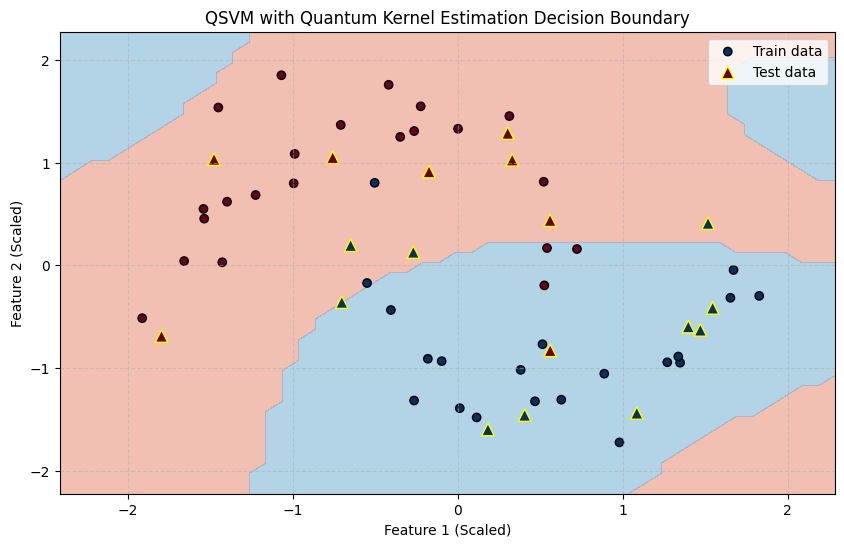

In [12]:
x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))

grid_points = np.c_[xx.ravel(), yy.ravel()]

print("\n--- Evaluating Decision Boundary across Feature Space Grid ---")
# Compute the kernel matrix between the evaluation grid points and the training points
grid_kernel_matrix = get_kernel_matrix(grid_points, X_train)
grid_predictions = qsvm_model.predict(grid_kernel_matrix)
grid_predictions = grid_predictions.reshape(xx.shape)

# Plotting
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, grid_predictions, levels=1, cmap="RdBu", alpha=0.5)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="RdBu", edgecolors="k", marker="o", label="Train data")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="RdBu", edgecolors="yellow", marker="^", s=80, label="Test data")

plt.title("QSVM with Quantum Kernel Estimation Decision Boundary")
plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Summary of Exploration: Quantum Kernel Estimation (QKE)

In this notebook, we successfully built and evaluated a hybrid classical-quantum classification pipeline using **Quantum Kernel Estimation (QKE)** to classify a non-linear dataset.

### 1. Dataset Preparation
* We generated a synthetic, non-linear **Moons Dataset** (`make_moons`) with 60 samples and added noise ($0.15$) to simulate a challenging decision boundary.
* The features were normalized using scikit-learn's `StandardScaler` to prepare them for quantum state encoding.
* The dataset was split into $70\%$ training (42 samples) and $30\%$ testing (18 samples).

### 2. Quantum Feature Map & Kernel Circuit
* We configured a 2-qubit quantum simulator device (`default.qubit`) using PennyLane.
* We designed an **Angle Embedding Map** to transition classical inputs into quantum Hilbert space:
  * Standard superposition is initialized via **Hadamard** gates.
  * $R_Z$ rotations encode classical coordinate values.
  * Entangling **CNOT** gates and non-linear interactive rotations ($x_0 \cdot x_1$) introduce quantum correlations.
* The **Quantum Kernel Circuit** computes the overlap (transition probability) between two mapped states $|\langle\phi(x_2) | \phi(x_1)\rangle|^2$ by applying the forward feature map for $x_1$ and the adjoint (inverse) feature map for $x_2$, then measuring the probability of returning to the $|00\rangle$ state.

### 3. Gram Matrix Computation & Classification
* We computed the $O(N^2)$ pairwise similarity matrices:
  * **Training Kernel Matrix** (size $42 \times 42$)
  * **Testing Kernel Matrix** (size $18 \times 42$)
* These precomputed quantum matrices were used to train and evaluate a classical **Support Vector Classifier (SVC)** from scikit-learn.
* **Performance Metrics attained:**
  * **Quantum Kernel Training Accuracy:** **88.10%**
  * **Quantum Kernel Testing Accuracy:** **72.22%**

### 4. Decision Boundary Visualization
* We projected a dense coordinate grid across the scaled feature space and calculated its similarity against all training points via our quantum kernel.
* The resulting decision boundary clearly separates the interleaved blue and red moons, validating that a classical linear classifier can resolve complex non-linear structures when mapped to high-dimensional quantum Hilbert spaces.